# 04 · Clustering y validación 2009–2024

Reproducción del clustering exploratorio, comparación de modelos, estabilidad, sensibilidad y validación temporal descriptiva. El modelo final del hackathon no está congelado.

Fuente: ZIPs CCPC del INE conservados en `datos/raw/`. Se trabaja sobre sus agregaciones verificables en `datos/processed/`. Los resultados representan **grupos estadísticos, no personas individuales**.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd().resolve()
if not (ROOT/'datos').exists():
    ROOT = ROOT.parent.parent
assert (ROOT/'datos'/'processed').exists(), f'Abra el proyecto raíz, no otro directorio: {ROOT}'
plt.rcParams.update({'figure.figsize':(9,4.3),'figure.dpi':110})


## Preparación de los features sin usar identificadores demográficos como predictores

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from src.modeling import FEATS
D=pd.read_csv(ROOT/'datos/processed/matriz_modelo_6_anios.csv')
D=D.loc[D.apto_modelo].reset_index(drop=True)
X=D[FEATS].to_numpy()
scale=StandardScaler().fit(X);Z=scale.transform(X)
print('n=',len(D),'features=',FEATS)
display(D[FEATS].describe().round(2))

n= 8541 features= ['media_presidencial', 'media_intermedia', 'cambio_presidencial_pp', 'cambio_intermedia_pp']


,media_presidencial,media_intermedia,cambio_presidencial_pp,cambio_intermedia_pp
count,8541.00,8541.00,8541.00,8541.00
mean,64.18,53.09,-2.25,13.24
std,12.14,13.87,10.08,14.37
min,10.32,8.85,-42.27,-40.12
25%,56.31,43.26,-8.45,2.10
50%,64.78,53.24,-2.45,12.28
75%,72.97,62.89,3.75,23.65
max,96.61,93.60,82.06,64.03


## Comparación de nueve variantes, con métricas reproducibles

,algoritmo,k,silhouette_muestra_2000,davies_bouldin,min_fraccion
0,KMeans,4,0.247,1.187,0.215
1,KMeans,5,0.232,1.218,0.147
2,KMeans,6,0.222,1.211,0.089
3,Birch,6,0.185,1.226,0.001
4,Birch,5,0.183,1.381,0.061
5,Birch,4,0.164,1.382,0.061
6,GaussianMixture,5,0.153,1.686,0.121
7,GaussianMixture,4,0.146,1.633,0.157
8,GaussianMixture,6,0.125,2.121,0.040


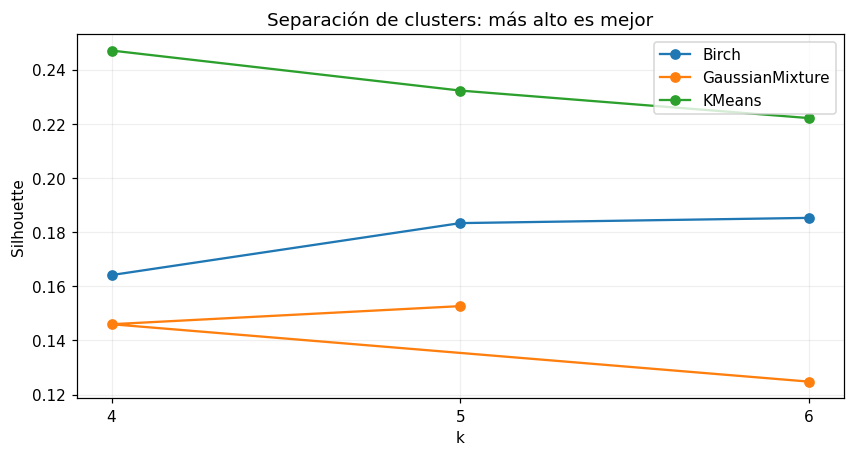

In [3]:
c=pd.read_csv(ROOT/'ml/resultados/comparacion_modelos.csv')
display(c.sort_values('silhouette_muestra_2000',ascending=False)[['algoritmo','k','silhouette_muestra_2000','davies_bouldin','min_fraccion']].round(3))
for algo,grupo in c.groupby('algoritmo'):
    plt.plot(grupo.k,grupo.silhouette_muestra_2000,marker='o',label=algo)
plt.xticks([4,5,6]);plt.xlabel('k');plt.ylabel('Silhouette');plt.title('Separación de clusters: más alto es mejor');plt.legend();plt.grid(alpha=.2);plt.show()

## Reentrenamiento independiente y verificación de resultados k=4 vs k=5

In [4]:
for k in [4,5]:
    kmodel=KMeans(n_clusters=k,n_init=20,random_state=42)
    labels=kmodel.fit_predict(Z)
    score=silhouette_score(Z,labels,sample_size=min(2000,len(Z)),random_state=64)
    print(f'KMeans k={k}, silhouette={score:.4f}, tamaños={np.bincount(labels).tolist()}')
print('Son puntuaciones de clustering, NO exactitud de predicción individual.')

KMeans k=4, silhouette=0.2471, tamaños=[2035, 1840, 2511, 2155]
KMeans k=5, silhouette=0.2323, tamaños=[1366, 1259, 1964, 2080, 1872]
Son puntuaciones de clustering, NO exactitud de predicción individual.


## Fichas de los cinco grupos exploratorios, distribuciones y limitaciones

,perfil_id,n_unidades,municipios,media_presidencial,media_intermedia,cambio_presidencial_pp,cambio_intermedia_pp
0,1,1366,655,46.61,34.57,-9.83,3.35
1,2,1872,900,58.98,45.01,0.30,18.68
2,3,1964,897,64.33,56.96,-9.05,0.21
3,4,1259,482,68.66,52.69,11.42,33.45
4,5,2080,949,77.56,69.11,-1.41,14.90


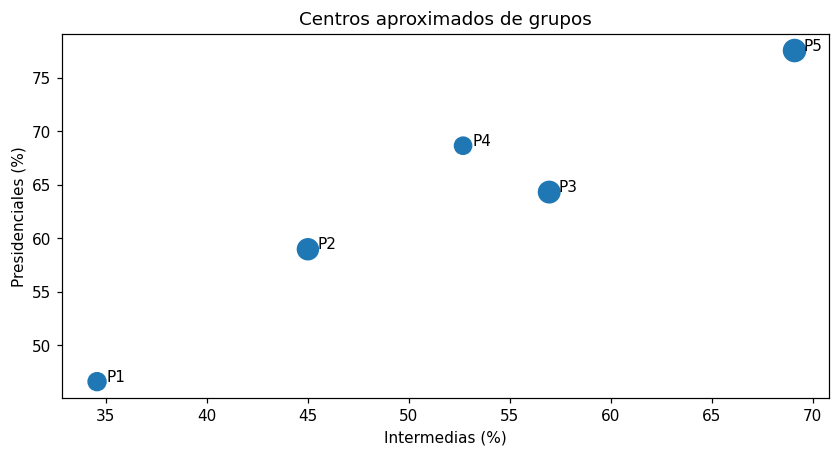

In [5]:
p=pd.read_csv(ROOT/'ml/resultados/fichas_perfiles_exploratorias.csv')
display(p[['perfil_id','n_unidades','municipios','media_presidencial','media_intermedia','cambio_presidencial_pp','cambio_intermedia_pp']].round(2))
ax=p.plot.scatter(x='media_intermedia',y='media_presidencial',s=p.n_unidades/10)
for _,r in p.iterrows():ax.annotate(f'P{int(r.perfil_id)}',(r.media_intermedia,r.media_presidencial),xytext=(6,0),textcoords='offset points')
ax.set(title='Centros aproximados de grupos',xlabel='Intermedias (%)',ylabel='Presidenciales (%)');plt.show()

## Estabilidad y temporalidad sin filtrar 2024 al entrenamiento de evaluación

In [6]:
import json
st=pd.read_csv(ROOT/'ml/resultados/estabilidad_semillas.csv')
sens=pd.read_csv(ROOT/'ml/resultados/sensibilidad.csv')
display(st.round(3));display(sens.round(3))
h=json.loads((ROOT/'ml/resultados/validacion_temporal_descriptiva.json').read_text())
print('Holdout descriptivo: entrenamiento 2009–2021; tasa 2024 retenida.')
print('Eta² 2024:',round(h['eta_cuadrada_tasa_2024'],3))
print('Esto NO demuestra capacidad de predicción causal ni resultados individuales.')

,algoritmo,k,ARI_semillas_media
0,KMeans,4,0.966
1,KMeans,5,0.974
2,KMeans,6,0.801


,k,ARI_escalador_robusto_vs_estandar,ARI_NS_hasta_10_por_ciento,unidades_NS_10pct
0,4,0.869,0.862,5671
1,5,0.794,0.863,5671
2,6,0.758,0.877,5671


Holdout descriptivo: entrenamiento 2009–2021; tasa 2024 retenida.
Eta² 2024: 0.544
Esto NO demuestra capacidad de predicción causal ni resultados individuales.
